<a href="https://colab.research.google.com/github/yimarbriceon/ingenieria-conocimiento-uncp/blob/master/mis-trabajos/laboratorio-3/Shells_vs_Pebbles_MobileNetV2_TL_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐚 Sistema inteligente de clasificación de conchas marinas y piedras mediante MobileNetV2

**Proyecto universitario — Clasificación binaria de imágenes con Transfer Learning**

| Campo | Detalle |
|-------|--------|
| **Tema** | Clasificación automática Shell (concha marina) vs Pebble (piedra) |
| **Arquitectura** | MobileNetV2 (ImageNet) + clasificador binario |
| **Estrategia** | Feature Extraction → Fine-Tuning selectivo |
| **Framework** | TensorFlow / Keras |
| **Entorno recomendado** | Google Colab + GPU |

---

### Objetivos de aprendizaje
1. Aplicar Transfer Learning (Feature Extraction) con MobileNetV2.
2. Realizar Fine-Tuning selectivo de las capas superiores del backbone.
3. Evaluar el modelo con métricas completas (Accuracy, Precision, Recall, F1-Score y Matriz de Confusión).
4. Comparar el rendimiento antes y después del Fine-Tuning.
5. Exportar el modelo entrenado para uso posterior.

## 1. Configuración del entorno

Verificamos la disponibilidad de GPU e instalamos/actualizamos las dependencias necesarias.

In [1]:
# Verificar GPU
import subprocess
gpu_info = subprocess.run(
    ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
    capture_output=True, text=True
)
if gpu_info.returncode == 0:
    print("✅ GPU detectada:")
    print(gpu_info.stdout.strip())
else:
    print("⚠️ No se detectó GPU. Se recomienda habilitar Runtime → Change runtime type → GPU.")

✅ GPU detectada:
Tesla T4, 15360 MiB


In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing import image_dataset_from_directory

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import os
import shutil
import random
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Reproducibilidad
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Carga y organización del dataset

### Fuente del dataset
- **Nombre**: Shells or Pebbles: An Image Classification Dataset  
- **Imágenes**: ≈ 4.284 JPG  
- **Clases**: `Shell` (conchas marinas) y `Pebble` (piedras)  
- **Licencia**: CC BY-SA 4.0  
- **Enlace Kaggle**: https://www.kaggle.com/datasets/vencerlanz09/shells-or-pebbles-an-image-classification-dataset  
- **Enlace Innovatiana**: https://www.innovatiana.com/en/datasets/shells-or-pebbles-classification

### Método de carga (automático y robusto)

En Google Colab la forma más fiable es **subir el archivo ZIP** del dataset desde tu computadora.  
El código siguiente:

1. Te permite subir el ZIP.
2. Lo extrae automáticamente.
3. Busca de forma recursiva las carpetas de las dos clases (Shells / Pebbles).
4. Cuenta las imágenes válidas.
5. Organiza el conjunto en train / val / test (70 % / 15 % / 15 %).

> **Cómo obtener el ZIP**: entra al enlace de Kaggle anterior → botón **Download** → descarga el archivo `.zip` a tu PC.

In [3]:
# ============================================================
# CARGA AUTOMÁTICA DEL DATASET EN GOOGLE COLAB
# ============================================================
# Método principal: subir el archivo ZIP desde tu computadora.
# ============================================================

from google.colab import files
import zipfile
import os
import shutil
from pathlib import Path

# Carpetas de trabajo
WORK_DIR = '/content'
RAW_EXTRACT_DIR = os.path.join(WORK_DIR, 'shells_pebbles_raw')
DATA_DIR = os.path.join(WORK_DIR, 'shells_pebbles_split')   # train/val/test

# Limpiar ejecuciones anteriores
for d in [RAW_EXTRACT_DIR, DATA_DIR]:
    if os.path.exists(d):
        shutil.rmtree(d)
os.makedirs(RAW_EXTRACT_DIR, exist_ok=True)

print("📤 Sube ahora el archivo ZIP del dataset (el que descargaste de Kaggle).")
print("   (Se abrirá el selector de archivos de Colab)\n")

uploaded = files.upload()   # <-- aquí subes el .zip

if not uploaded:
    raise RuntimeError("No se subió ningún archivo. Vuelve a ejecutar esta celda y selecciona el ZIP.")

# Tomar el primer archivo subido
zip_filename = list(uploaded.keys())[0]
zip_path = os.path.join(WORK_DIR, zip_filename)

print(f"\n✅ Archivo recibido: {zip_filename} ({os.path.getsize(zip_path)/1e6:.1f} MB)")

# Extraer
print("📦 Extrayendo el archivo ZIP...")
with zipfile.ZipFile(zip_path, 'r') as zf:
    zf.extractall(RAW_EXTRACT_DIR)

print(f"✅ Extracción completada en: {RAW_EXTRACT_DIR}")

# Mostrar estructura de primer nivel
print("\n📁 Contenido extraído (primer nivel):")
for item in sorted(os.listdir(RAW_EXTRACT_DIR)):
    full = os.path.join(RAW_EXTRACT_DIR, item)
    if os.path.isdir(full):
        print(f"   📂 {item}/")
    else:
        print(f"   📄 {item}")


📤 Sube ahora el archivo ZIP del dataset (el que descargaste de Kaggle).
   (Se abrirá el selector de archivos de Colab)



Saving archive.zip to archive.zip

✅ Archivo recibido: archive.zip (204.8 MB)
📦 Extrayendo el archivo ZIP...
✅ Extracción completada en: /content/shells_pebbles_raw

📁 Contenido extraído (primer nivel):
   📂 Pebbles/
   📂 Shells/


In [4]:
# ============================================================
# DETECCIÓN AUTOMÁTICA DE LAS CARPETAS DE CLASES
# ============================================================

def find_class_folders(root_dir):
    """
    Busca de forma recursiva carpetas que correspondan a Shell y Pebble.
    Devuelve un diccionario: {'Shell': path, 'Pebble': path}
    """
    shell_keywords = ['shell', 'shells', 'concha', 'conchas']
    pebble_keywords = ['pebble', 'pebbles', 'piedra', 'piedras', 'stone', 'stones']

    found = {}
    for dirpath, dirnames, filenames in os.walk(root_dir):
        dirname_lower = os.path.basename(dirpath).lower()
        # Contar imágenes válidas en esta carpeta
        imgs = [f for f in filenames if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))]
        if len(imgs) < 5:          # ignorar carpetas casi vacías
            continue

        if any(k in dirname_lower for k in shell_keywords) and 'Shell' not in found:
            found['Shell'] = dirpath
            print(f"   ✅ Shell  → {dirpath}  ({len(imgs)} imágenes)")
        elif any(k in dirname_lower for k in pebble_keywords) and 'Pebble' not in found:
            found['Pebble'] = dirpath
            print(f"   ✅ Pebble → {dirpath}  ({len(imgs)} imágenes)")

        if len(found) == 2:
            break
    return found

print("🔍 Buscando carpetas de clases (Shell / Pebble)...")
class_folders = find_class_folders(RAW_EXTRACT_DIR)

if len(class_folders) != 2:
    print("\n❌ No se encontraron las dos carpetas de clases.")
    print("   Estructura completa del dataset extraído:")
    for root, dirs, files in os.walk(RAW_EXTRACT_DIR):
        level = root.replace(RAW_EXTRACT_DIR, '').count(os.sep)
        indent = '  ' * level
        print(f"{indent}{os.path.basename(root)}/")
        for d in dirs[:8]:
            print(f"{indent}  📂 {d}/")
        imgs = [f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))]
        if imgs:
            print(f"{indent}  🖼  {len(imgs)} imágenes")
    raise RuntimeError(
        "No se detectaron las carpetas 'Shell' y 'Pebble'. "
        "Revisa la estructura impresa arriba e informa al docente."
    )

print("\n✅ Carpetas de clases detectadas correctamente.")


🔍 Buscando carpetas de clases (Shell / Pebble)...
   ✅ Pebble → /content/shells_pebbles_raw/Pebbles  (2743 imágenes)
   ✅ Shell  → /content/shells_pebbles_raw/Shells  (1541 imágenes)

✅ Carpetas de clases detectadas correctamente.


In [5]:
# ============================================================
# ORGANIZACIÓN ESTRATIFICADA train / val / test (70 % / 15 % / 15 %)
# ============================================================

def organize_split(class_folders, dest_dir, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    random.seed(seed)
    os.makedirs(dest_dir, exist_ok=True)

    stats = {'train': {}, 'val': {}, 'test': {}}
    image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

    for class_name, src_folder in class_folders.items():
        images = [f for f in os.listdir(src_folder)
                  if f.lower().endswith(image_extensions)]
        random.shuffle(images)

        n = len(images)
        n_train = int(n * train_ratio)
        n_val   = int(n * val_ratio)

        splits = {
            'train': images[:n_train],
            'val'  : images[n_train:n_train + n_val],
            'test' : images[n_train + n_val:]
        }

        for split_name, img_list in splits.items():
            target_dir = os.path.join(dest_dir, split_name, class_name)
            os.makedirs(target_dir, exist_ok=True)
            for fname in img_list:
                shutil.copy2(os.path.join(src_folder, fname),
                             os.path.join(target_dir, fname))
            stats[split_name][class_name] = len(img_list)

    return stats

print("📂 Organizando dataset en train / val / test ...")
stats = organize_split(class_folders, DATA_DIR)

print("\n✅ Organización finalizada:")
total = 0
for split in ['train', 'val', 'test']:
    s = stats[split]
    n = sum(s.values())
    total += n
    print(f"   {split:5s}: {s}  → {n} imágenes")
print(f"\n   TOTAL: {total} imágenes")

# Verificación rápida de integridad
print("\n🔎 Verificación de integridad:")
for split in ['train', 'val', 'test']:
    for cls in ['Shell', 'Pebble']:
        path = os.path.join(DATA_DIR, split, cls)
        n = len([f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        print(f"   {split}/{cls}: {n} archivos")


📂 Organizando dataset en train / val / test ...

✅ Organización finalizada:
   train: {'Pebble': 1920, 'Shell': 1078}  → 2998 imágenes
   val  : {'Pebble': 411, 'Shell': 231}  → 642 imágenes
   test : {'Pebble': 412, 'Shell': 232}  → 644 imágenes

   TOTAL: 4284 imágenes

🔎 Verificación de integridad:
   train/Shell: 1078 archivos
   train/Pebble: 1920 archivos
   val/Shell: 231 archivos
   val/Pebble: 411 archivos
   test/Shell: 232 archivos
   test/Pebble: 412 archivos


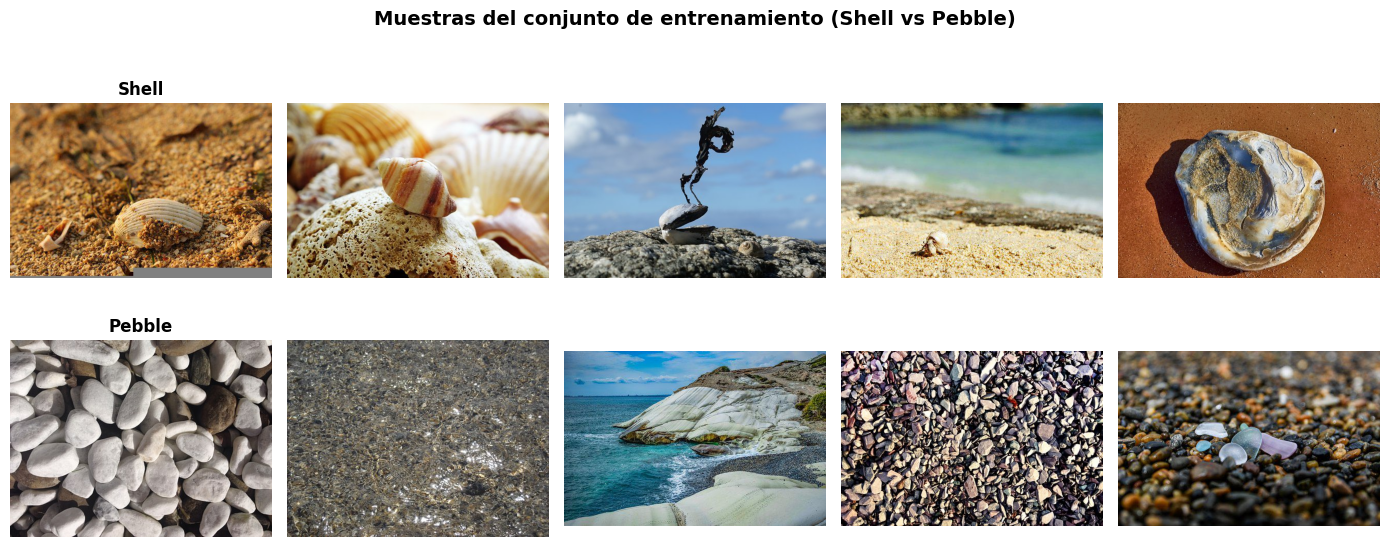


✅ Dataset listo. DATA_DIR = /content/shells_pebbles_split
   Las celdas siguientes usarán esta variable automáticamente.


In [6]:
# ============================================================
# VISUALIZACIÓN RÁPIDA DE MUESTRAS DESPUÉS DE LA ORGANIZACIÓN
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, cls in enumerate(['Shell', 'Pebble']):
    folder = os.path.join(DATA_DIR, 'train', cls)
    imgs = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.jpeg','.png'))][:5]
    for col, fname in enumerate(imgs):
        ax = axes[row, col]
        img = Image.open(os.path.join(folder, fname))
        ax.imshow(img)
        ax.set_title(cls if col == 0 else '', fontsize=12, fontweight='bold')
        ax.axis('off')
plt.suptitle('Muestras del conjunto de entrenamiento (Shell vs Pebble)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✅ Dataset listo. DATA_DIR =", DATA_DIR)
print("   Las celdas siguientes usarán esta variable automáticamente.")


## 3. Exploración y visualización del dataset

In [7]:
CLASS_NAMES = ['Pebble', 'Shell']   # se actualizará con lo que detecte Keras
NUM_CLASSES = 2
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Cargar datasets (DATA_DIR ya está definido en la sección anterior)
train_ds_raw = image_dataset_from_directory(
    os.path.join(DATA_DIR, 'train'),
    labels='inferred',
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=True,
    seed=SEED
)

val_ds_raw = image_dataset_from_directory(
    os.path.join(DATA_DIR, 'val'),
    labels='inferred',
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=False,
    seed=SEED
)

test_ds_raw = image_dataset_from_directory(
    os.path.join(DATA_DIR, 'test'),
    labels='inferred',
    label_mode='binary',
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=False,
    seed=SEED
)

print(f"Clases detectadas por Keras: {train_ds_raw.class_names}")
CLASS_NAMES = train_ds_raw.class_names
print(f"Mapeo: 0 → {CLASS_NAMES[0]}, 1 → {CLASS_NAMES[1]}")
print(f"DATA_DIR = {DATA_DIR}")


Found 2998 files belonging to 2 classes.
Found 642 files belonging to 2 classes.
Found 644 files belonging to 2 classes.
Clases detectadas por Keras: ['Pebble', 'Shell']
Mapeo: 0 → Pebble, 1 → Shell
DATA_DIR = /content/shells_pebbles_split


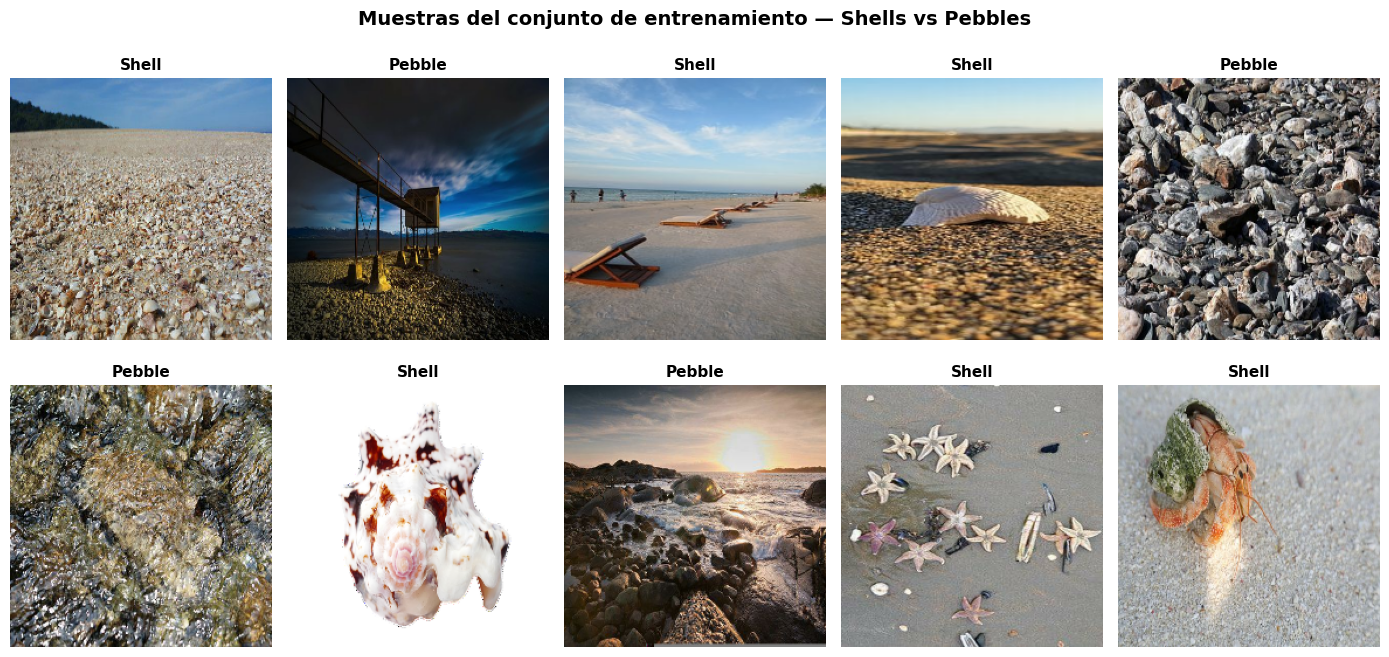

In [9]:
# Visualizar muestras aleatorias
plt.figure(figsize=(14, 7))
for i, (img, label) in enumerate(train_ds_raw.take(10)):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(img.numpy().astype('uint8'))

    # Convertir la etiqueta de forma segura (funciona con escalar o array)
    label_idx = int(np.array(label).flatten()[0])
    plt.title(CLASS_NAMES[label_idx], fontsize=11, fontweight='bold')
    plt.axis('off')

plt.suptitle('Muestras del conjunto de entrenamiento — Shells vs Pebbles',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Distribución de clases:
   Train : {'Pebble': np.int64(1920), 'Shell': np.int64(1078)}
   Val   : {'Pebble': np.int64(411), 'Shell': np.int64(231)}
   Test  : {'Pebble': np.int64(412), 'Shell': np.int64(232)}


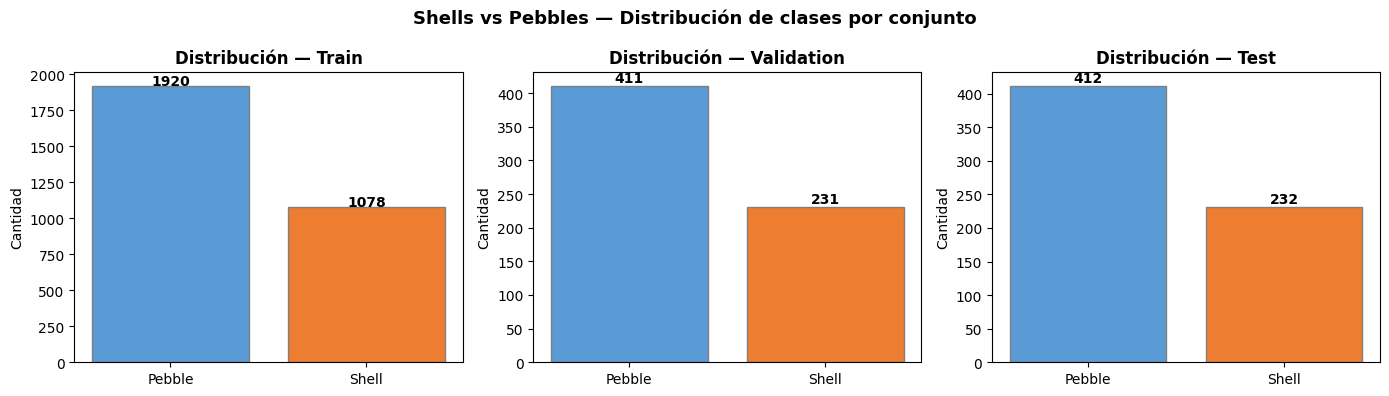

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Distribución de clases corregida
def count_labels(dataset):
    labels = []
    for _, batch_labels in dataset:
        labels.extend(batch_labels.numpy().flatten())

    labels = [int(l) for l in labels]
    unique, counts = np.unique(labels, return_counts=True)
    return dict(zip([CLASS_NAMES[u] for u in unique], counts))

train_dist = count_labels(train_ds_raw)
val_dist   = count_labels(val_ds_raw)
test_dist  = count_labels(test_ds_raw)

print("Distribución de clases:")
print(f"   Train : {train_dist}")
print(f"   Val   : {val_dist}")
print(f"   Test  : {test_dist}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, dist, title in zip(axes, [train_dist, val_dist, test_dist],
                            ['Train', 'Validation', 'Test']):
    bars = ax.bar(dist.keys(), dist.values(), color=['#5B9BD5', '#ED7D31'], edgecolor='gray')
    ax.set_title(f'Distribución — {title}', fontweight='bold')
    ax.set_ylabel('Cantidad')
    for bar, count in zip(bars, dist.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(count), ha='center', fontweight='bold')

plt.suptitle('Shells vs Pebbles — Distribución de clases por conjunto',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Preprocesamiento y Data Augmentation

**Importante**:  
- MobileNetV2 espera imágenes de **224×224**.  
- Utilizamos **exclusivamente** `tf.keras.applications.mobilenet_v2.preprocess_input`.  
- **No** aplicar `Rescaling(1./255)` ni normalizaciones adicionales incompatibles.  
- Data Augmentation **solo** se aplica al conjunto de entrenamiento.

In [13]:
# Capa de Data Augmentation (solo train)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name='data_augmentation')

def preprocess_train(image, label):
    image = tf.cast(image, tf.float32)
    image = data_augmentation(image, training=True)
    image = preprocess_input(image)          # ← preprocess de MobileNetV2
    return image, label

def preprocess_val_test(image, label):
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)          # ← mismo preprocess, sin augmentation
    return image, label

# Pipelines optimizados
train_ds = (train_ds_raw
            .map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
            .shuffle(1000, seed=SEED)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

val_ds = (val_ds_raw
          .map(preprocess_val_test, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

test_ds = (test_ds_raw
           .map(preprocess_val_test, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(BATCH_SIZE)
           .prefetch(tf.data.AUTOTUNE))

print("✅ Pipelines de datos listos (augmentation solo en train).")

✅ Pipelines de datos listos (augmentation solo en train).


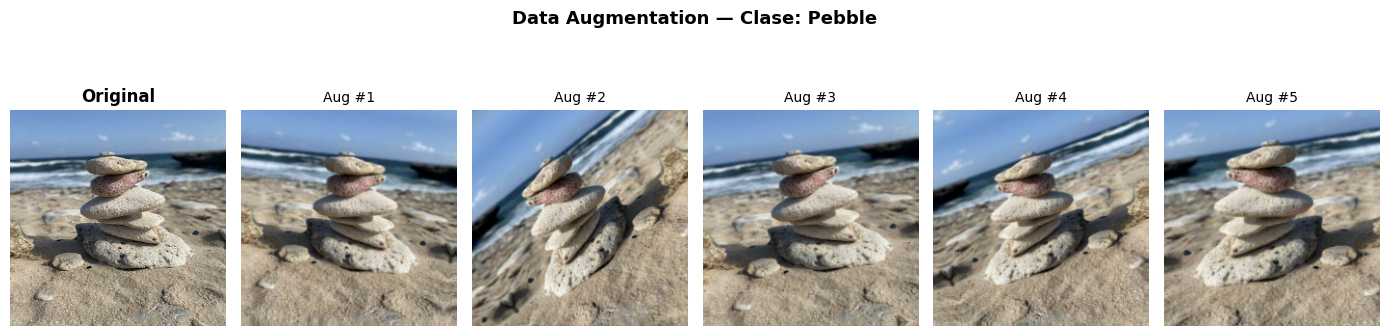

In [16]:
# Visualizar efecto del Data Augmentation corregido
sample_img, sample_label = next(iter(train_ds_raw))

# Asegurar que sample_img sea un tensor 3D de forma (224, 224, 3)
if len(sample_img.shape) == 4:
    img_to_show = sample_img[0]
else:
    img_to_show = sample_img

plt.figure(figsize=(14, 4))
plt.subplot(1, 6, 1)
plt.imshow(img_to_show.numpy().astype('uint8'))
plt.title('Original', fontweight='bold')
plt.axis('off')

for i in range(5):
    # Pasamos la imagen directamente en formato 3D (sin tf.expand_dims)
    aug = data_augmentation(img_to_show, training=True)
    plt.subplot(1, 6, i + 2)
    plt.imshow(aug.numpy().astype('uint8'))
    plt.title(f'Aug #{i+1}', fontsize=10)
    plt.axis('off')

# Extraer el valor escalar de la etiqueta de forma segura
label_idx = int(sample_label.numpy().item()) if hasattr(sample_label.numpy(), 'item') else int(sample_label.numpy())

plt.suptitle(f'Data Augmentation — Clase: {CLASS_NAMES[label_idx]}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Construcción del modelo — Feature Extraction (MobileNetV2)

**Estrategia**:
1. Cargar MobileNetV2 pre-entrenado en ImageNet **sin** la cabeza de clasificación (`include_top=False`).
2. **Congelar** todo el backbone (`trainable = False`).
3. Añadir un clasificador binario personalizado con salida **sigmoid**.

In [17]:
# Backbone MobileNetV2
base_model = MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False          # ← Feature Extraction: todo congelado

# Modelo completo
inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)   # BN en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)   # ← salida binaria

model_fe = models.Model(inputs, outputs, name='ShellsPebbles_MobileNetV2_FE')

# Resumen de parámetros
total_params = model_fe.count_params()
trainable_params = sum(tf.size(w).numpy() for w in model_fe.trainable_weights)
print("📐 MobileNetV2 — Feature Extraction")
print(f"   Total de parámetros : {total_params:,}")
print(f"   Entrenables         : {trainable_params:,}")
print(f"   Congelados          : {total_params - trainable_params:,}")
model_fe.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
📐 MobileNetV2 — Feature Extraction
   Total de parámetros : 2,427,201
   Entrenables         : 166,657
   Congelados          : 2,260,544


Model: "ShellsPebbles_MobileNetV2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,201 (9.26 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 6. Compilación y entrenamiento (Feature Extraction)

In [19]:
model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("🚀 Iniciando entrenamiento — Feature Extraction...")
history_fe = model_fe.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop, reduce_lr]
)

print(f"\n🏆 Mejor val_accuracy (FE): {max(history_fe.history['val_accuracy']):.4f}")

🚀 Iniciando entrenamiento — Feature Extraction...
Epoch 1/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 70s 389ms/step - accuracy: 0.8856 - loss: 0.2757 - precision: 0.8628 - recall: 0.8108 - val_accuracy: 0.8660 - val_loss: 0.3560 - val_precision: 0.9394 - val_recall: 0.6710 - learning_rate: 0.0010
Epoch 2/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 58s 285ms/step - accuracy: 0.8823 - loss: 0.2692 - precision: 0.8530 - recall: 0.8126 - val_accuracy: 0.8785 - val_loss: 0.3273 - val_precision: 0.9422 - val_recall: 0.7056 - learning_rate: 0.0010
Epoch 3/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 38s 281ms/step - accuracy: 0.8926 - loss: 0.2633 - precision: 0.8699 - recall: 0.8247 - val_accuracy: 0.8707 - val_loss: 0.3124 - val_precision: 0.8524 - val_recall: 0.7749 - learning_rate: 0.0010
Epoch 4/20
94/94 ━━━━━━━━━━━━━━━━━━━━ 38s 283ms/step - accuracy: 0.9076 - loss: 0.2427 - precision: 0.8885 - recall: 0.8497 - val_accuracy: 0.8925 - val_loss: 0.3023 - val_precision: 0.9309 - val_recall: 0.7576 - learning_rate: 0.0010
Epoch 5/20

## 7. Curvas de aprendizaje — Feature Extraction

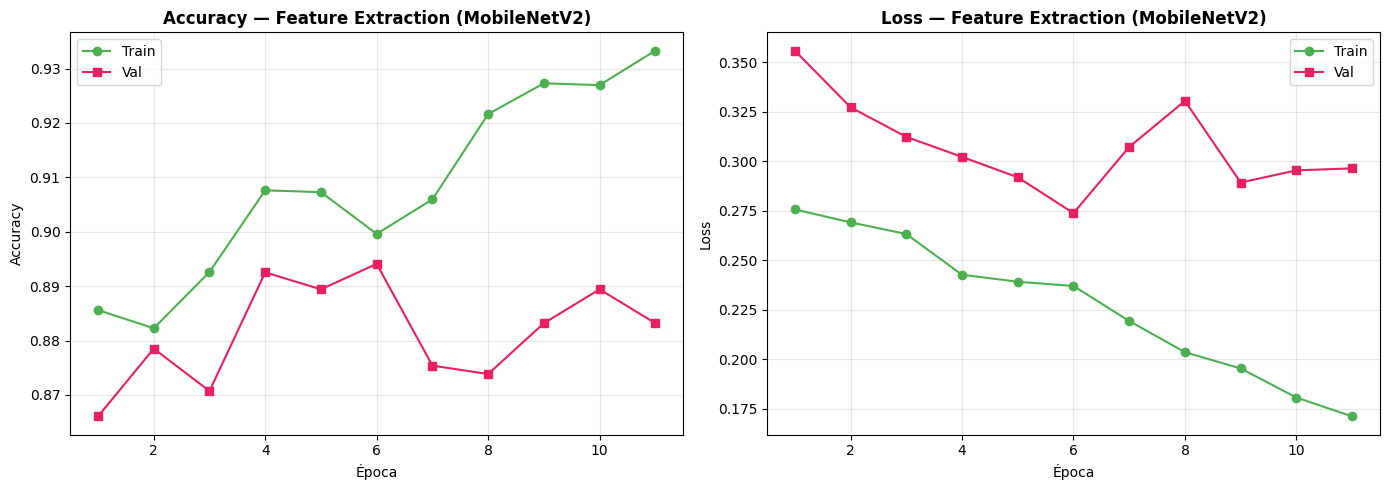

In [20]:
def plot_history(history, title_suffix=''):
    ep = range(1, len(history.history['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(ep, history.history['accuracy'], 'o-', label='Train', color='#4CAF50')
    axes[0].plot(ep, history.history['val_accuracy'], 's-', label='Val', color='#E91E63')
    axes[0].set_title(f'Accuracy {title_suffix}', fontweight='bold')
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(ep, history.history['loss'], 'o-', label='Train', color='#4CAF50')
    axes[1].plot(ep, history.history['val_loss'], 's-', label='Val', color='#E91E63')
    axes[1].set_title(f'Loss {title_suffix}', fontweight='bold')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_fe, '— Feature Extraction (MobileNetV2)')

## 8. Evaluación detallada — Feature Extraction


📊 Resultados en conjunto Test (Feature Extraction)
Accuracy  : 0.8602
Precision : 0.8737
Recall    : 0.7155
F1-Score  : 0.7867

Classification Report:
              precision    recall  f1-score   support

      Pebble     0.8546    0.9417    0.8961       412
       Shell     0.8737    0.7155    0.7867       232

    accuracy                         0.8602       644
   macro avg     0.8642    0.8286    0.8414       644
weighted avg     0.8615    0.8602    0.8567       644



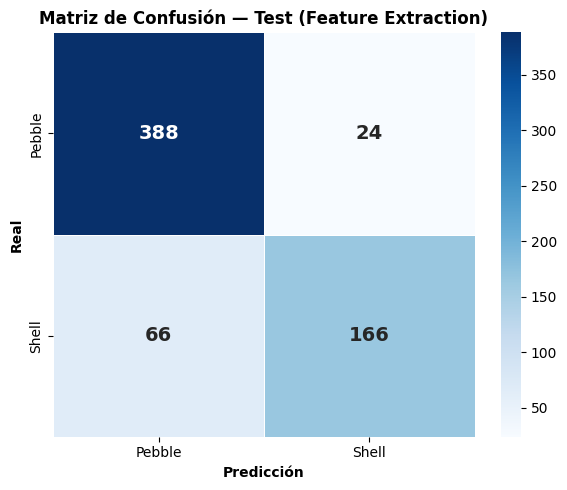

In [21]:
def evaluate_model(model, dataset, set_name='Test'):
    y_true, y_pred = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_pred.extend((preds > 0.5).astype(int).flatten())
        y_true.extend(labels.numpy().astype(int).flatten())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)

    print(f"\n📊 Resultados en conjunto {set_name}")
    print("=" * 55)
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax,
                linewidths=0.5, annot_kws={'size': 14, 'fontweight': 'bold'})
    ax.set_xlabel('Predicción', fontweight='bold')
    ax.set_ylabel('Real', fontweight='bold')
    ax.set_title(f'Matriz de Confusión — {set_name}', fontweight='bold')
    plt.tight_layout()
    plt.show()

    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1, 'cm': cm}

results_fe = evaluate_model(model_fe, test_ds, set_name='Test (Feature Extraction)')

## 9. Fine-Tuning selectivo

Descongelamos las **últimas capas** del backbone MobileNetV2 y re-entrenamos con una tasa de aprendizaje mucho más baja para adaptar los features de alto nivel al dominio de conchas y piedras.

In [22]:
# Descongelar el backbone
base_model.trainable = True

# Congelar las capas tempranas (dejar solo las últimas N entrenables)
fine_tune_at = 100          # descongelar a partir de la capa 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Capas del backbone: {len(base_model.layers)}")
print(f"Capas congeladas   : {fine_tune_at}")
print(f"Capas entrenables  : {len(base_model.layers) - fine_tune_at}")

trainable_params_ft = sum(tf.size(w).numpy() for w in model_fe.trainable_weights)
print(f"Parámetros entrenables ahora: {trainable_params_ft:,}")

Capas del backbone: 154
Capas congeladas   : 100
Capas entrenables  : 54
Parámetros entrenables ahora: 2,028,097


In [23]:
# Recompilar con learning rate bajo
model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # ← LR mucho más bajo
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

early_stop_ft = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_ft = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

print("🚀 Iniciando Fine-Tuning...")
history_ft = model_fe.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop_ft, reduce_lr_ft]
)

print(f"\n🏆 Mejor val_accuracy (Fine-Tuning): {max(history_ft.history['val_accuracy']):.4f}")

🚀 Iniciando Fine-Tuning...
Epoch 1/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 87s 525ms/step - accuracy: 0.8602 - loss: 0.3311 - precision: 0.8177 - recall: 0.7866 - val_accuracy: 0.9034 - val_loss: 0.3025 - val_precision: 0.9204 - val_recall: 0.8009 - learning_rate: 1.0000e-05
Epoch 2/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 45s 296ms/step - accuracy: 0.8669 - loss: 0.3129 - precision: 0.8293 - recall: 0.7931 - val_accuracy: 0.8972 - val_loss: 0.3195 - val_precision: 0.9104 - val_recall: 0.7922 - learning_rate: 1.0000e-05
Epoch 3/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.8708 - loss: 0.3112 - precision: 0.8253 - recall: 0.8108
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 297ms/step - accuracy: 0.8632 - loss: 0.3135 - precision: 0.8243 - recall: 0.7876 - val_accuracy: 0.8972 - val_loss: 0.3280 - val_precision: 0.9231 - val_recall: 0.7792 - learning_rate: 1.0000e-05
Epoch 4/15
94/94 ━━━━━━━━━━━━━━━━━━━━ 39s 295ms/step - accuracy: 0.8

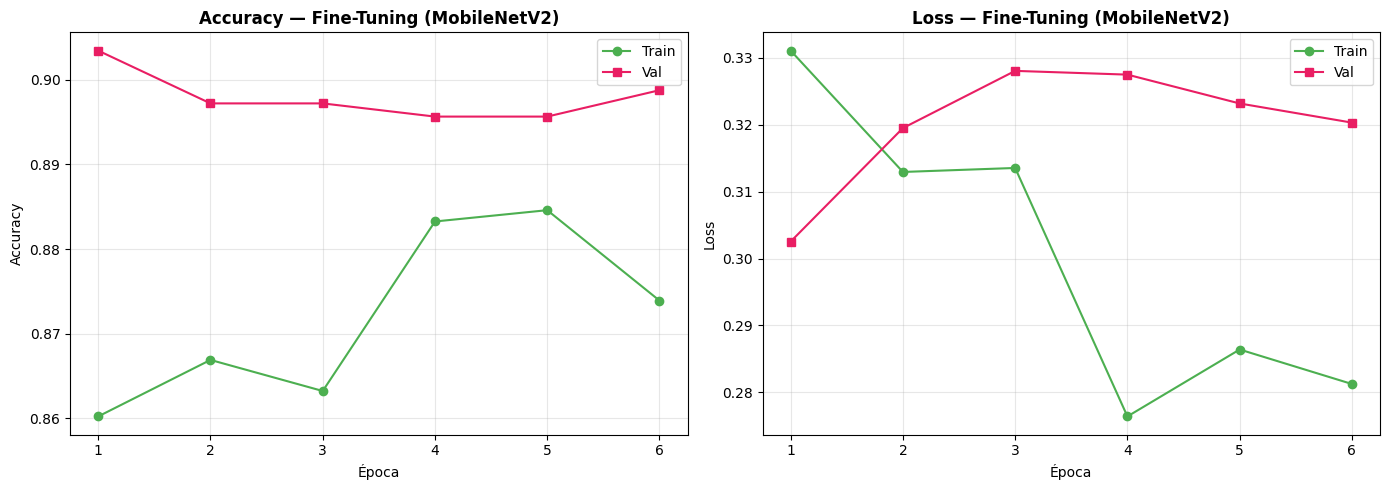

In [24]:
plot_history(history_ft, '— Fine-Tuning (MobileNetV2)')

## 10. Evaluación final después de Fine-Tuning


📊 Resultados en conjunto Test (Fine-Tuning)
Accuracy  : 0.8711
Precision : 0.8782
Recall    : 0.7457
F1-Score  : 0.8065

Classification Report:
              precision    recall  f1-score   support

      Pebble     0.8680    0.9417    0.9034       412
       Shell     0.8782    0.7457    0.8065       232

    accuracy                         0.8711       644
   macro avg     0.8731    0.8437    0.8550       644
weighted avg     0.8717    0.8711    0.8685       644



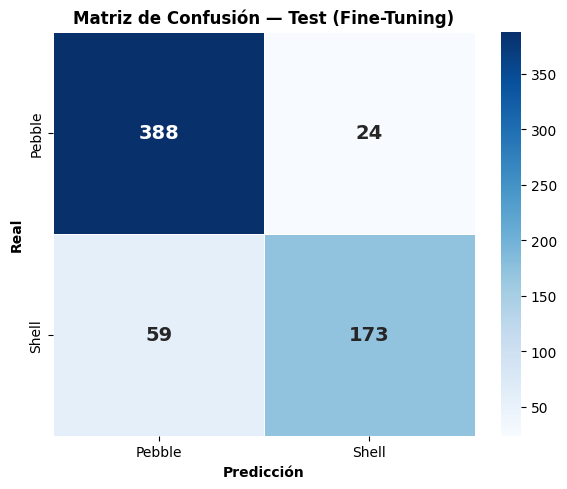

In [25]:
results_ft = evaluate_model(model_fe, test_ds, set_name='Test (Fine-Tuning)')

## 11. Comparación Feature Extraction vs Fine-Tuning


📊 TABLA COMPARATIVA
  Métrica  Feature Extraction  Fine-Tuning
 Accuracy            0.860248     0.871118
Precision            0.873684     0.878173
   Recall            0.715517     0.745690
 F1-Score            0.786730     0.806527


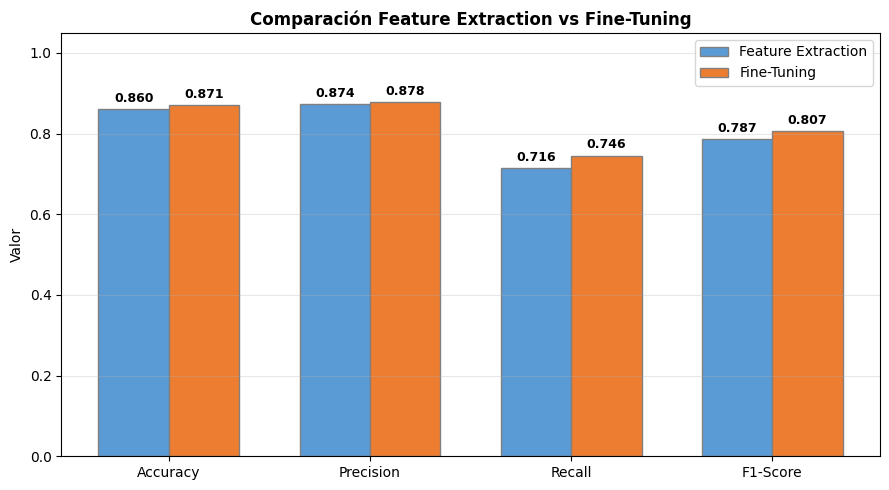

In [26]:
comparison = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Feature Extraction': [
        results_fe['accuracy'], results_fe['precision'],
        results_fe['recall'], results_fe['f1']
    ],
    'Fine-Tuning': [
        results_ft['accuracy'], results_ft['precision'],
        results_ft['recall'], results_ft['f1']
    ]
})

print("\n📊 TABLA COMPARATIVA")
print("=" * 50)
print(comparison.to_string(index=False))

# Gráfico comparativo
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(comparison['Métrica']))
width = 0.35
bars1 = ax.bar(x - width/2, comparison['Feature Extraction'], width,
               label='Feature Extraction', color='#5B9BD5', edgecolor='gray')
bars2 = ax.bar(x + width/2, comparison['Fine-Tuning'], width,
               label='Fine-Tuning', color='#ED7D31', edgecolor='gray')

ax.set_ylabel('Valor')
ax.set_title('Comparación Feature Extraction vs Fine-Tuning', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(comparison['Métrica'])
ax.legend()
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 12. Prueba del modelo con imágenes individuales

Función utilitaria para predecir sobre una imagen nueva.

In [33]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def predict_image(model, img_path, class_names=CLASS_NAMES):
    """Predice la clase de una imagen individual."""
    img = load_img(img_path, target_size=IMG_SIZE)
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    pred = model.predict(img_array, verbose=0)[0][0]
    label_idx = 1 if pred >= 0.5 else 0
    confidence = pred if pred >= 0.5 else 1 - pred

    plt.figure(figsize=(5, 5))
    plt.imshow(load_img(img_path))
    plt.title(f'Predicción: {class_names[label_idx]}\nConfianza: {confidence:.2%}',
              fontweight='bold')
    plt.axis('off')
    plt.show()

    return class_names[label_idx], confidence

# Ejemplo de uso (descomenta y cambia la ruta):
# predict_image(model_fe, '/content/ruta/a/tu/imagen.jpg')

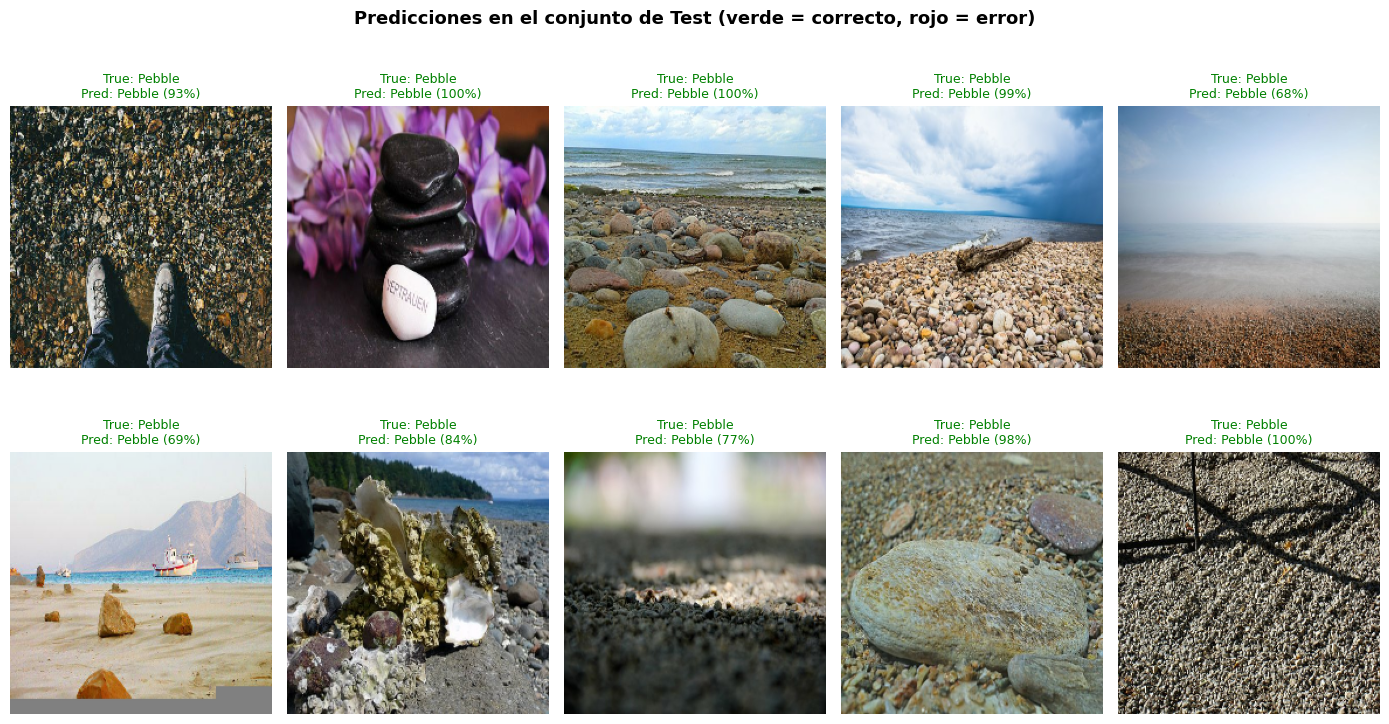

In [35]:
# Mostrar algunas predicciones del conjunto de test
plt.figure(figsize=(14, 8))
count = 0

# Si tu modelo se llama 'model', déjalo así. Si se llama 'model_fe' u otro, cámbialo aquí:
modelo_a_usar = model_fe  # O model_fe

for images, labels in test_ds.take(1):
    preds = modelo_a_usar.predict(images, verbose=0)
    for i in range(min(10, images.shape[0])):
        ax = plt.subplot(2, 5, count + 1)

        # Recuperar imagen procesada para visualización
        img_display = images[i].numpy()
        img_display = (img_display + 1.0) / 2.0
        img_display = np.clip(img_display, 0, 1)
        plt.imshow(img_display)

        # Extracción segura de la etiqueta real
        label_val = labels[i].numpy()
        if label_val.ndim > 0:
            label_val = label_val.item()
        true_label = CLASS_NAMES[int(label_val)]

        # Predicción y confianza
        pred_prob = preds[i][0]
        pred_label = CLASS_NAMES[1 if pred_prob >= 0.5 else 0]
        conf = pred_prob if pred_prob >= 0.5 else (1 - pred_prob)

        color = 'green' if true_label == pred_label else 'red'
        plt.title(f'True: {true_label}\nPred: {pred_label} ({conf:.0%})',
                  color=color, fontsize=9)
        plt.axis('off')
        count += 1

plt.suptitle('Predicciones en el conjunto de Test (verde = correcto, rojo = error)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 13. Guardado y exportación del modelo

In [36]:
# Guardar el modelo final (después de Fine-Tuning)
MODEL_PATH = '/content/shells_pebbles_mobilenetv2_ft.keras'
model_fe.save(MODEL_PATH)
print(f"✅ Modelo guardado en: {MODEL_PATH}")

# También en formato HDF5 (opcional, mayor compatibilidad)
MODEL_PATH_H5 = '/content/shells_pebbles_mobilenetv2_ft.h5'
model_fe.save(MODEL_PATH_H5)
print(f"✅ Modelo guardado también en: {MODEL_PATH_H5}")

# Verificar carga
loaded_model = tf.keras.models.load_model(MODEL_PATH)
print("✅ Modelo recargado correctamente.")
print(f"   Capas: {len(loaded_model.layers)}")

✅ Modelo guardado en: /content/shells_pebbles_mobilenetv2_ft.keras
✅ Modelo guardado también en: /content/shells_pebbles_mobilenetv2_ft.h5
✅ Modelo recargado correctamente.
   Capas: 8


## 14. Resumen final del proyecto

| Aspecto | Detalle |
|---------|--------|
| **Dataset** | Shells or Pebbles (≈ 4.284 imágenes) |
| **Split** | 70 % train / 15 % val / 15 % test (estratificado) |
| **Backbone** | MobileNetV2 (ImageNet) |
| **Estrategia 1** | Feature Extraction (backbone congelado) |
| **Estrategia 2** | Fine-Tuning (últimas capas descongeladas + LR bajo) |
| **Augmentation** | Flip, Rotation, Zoom, Contrast |
| **Preprocesamiento** | `mobilenet_v2.preprocess_input` |
| **Salida** | Sigmoid (clasificación binaria) |
| **Métricas** | Accuracy, Precision, Recall, F1-Score, Matriz de Confusión |
| **Regularización** | Dropout + EarlyStopping + ReduceLROnPlateau |

### Conclusiones esperadas
- Feature Extraction ya alcanza un rendimiento sólido gracias a los features transferidos de ImageNet.
- Fine-Tuning suele mejorar ligeramente la precisión al adaptar los filtros de alto nivel al dominio específico de conchas y piedras.
- El modelo es ligero y adecuado para despliegue en dispositivos móviles (objetivo original de MobileNetV2).

---
*Proyecto académico de clasificación de imágenes con Transfer Learning — Compatible con Google Colab + GPU*